# Repeated integrals in cosmology

In inference, the same integrals are needed for many cosmologies. `pylevin` determines the subintervals (the bisection) in the first call and stores every integral as a quadrature rule in the second; after `update_integrand`, later calls only evaluate these rules. This tutorial checks that this is accurate across a realistic range of cosmologies, for the correlation function multipoles of the `pylevin` paper:

$$\xi_\ell(s, z) = \frac{i^\ell}{2\pi^2}\int k^2 P_\ell(k, z)\, j_\ell(ks)\, \mathrm{d}k\,,$$

with the Kaiser multipoles $P_0 = (b^2 + 2bf/3 + f^2/5)P$, $P_2 = (4bf/3 + 4f^2/7)P$ and $P_4 = 8f^2P/35$ of the linear matter power spectrum $P(k, z)$, bias $b = 2$ and growth rate $f(z)$, for $\ell = 0, 2, 4$ at six redshifts.

For each cosmology we compare three ways of integrating:

1. `update_integrand` on the instance set up for the fiducial cosmology,
2. the exported quadrature rules of that instance (`get_quadrature`), with the power spectrum evaluated directly at the nodes,
3. the exported rules combined with the spline of the samples into one matrix, which integrates by a matrix product,
4. a new instance, which determines its own subintervals for this cosmology,

and also `hankl`, which uses FFTLog. The power spectra use CCL's Eisenstein & Hu transfer function, so that no Boltzmann code is needed; `transfer_function = "boltzmann_camb"` works the same way.

In [1]:
import time, timeit
import numpy as np
import matplotlib.pyplot as plt
import pyccl as ccl
import hankl
import scipy.sparse as sparse
from scipy.interpolate import CubicSpline
from scipy.special import spherical_jn
import pylevin as levin

## Setup

All 1440 integrals, 80 separations for three multipoles at six redshifts, use one diagonal instance: variable `i` integrates the integrand `integrand_all[i]`, one of the 18 functions $k^2 P_\ell(k, z)$, sampled on 1024 wavenumbers.

In [2]:
k = np.logspace(-4, 1, 2**10) # wavenumbers of the samples [1/Mpc]
a = np.linspace(1, 0.4, 6) # scale factors of the six redshifts
s = np.linspace(2e-1, 3e2, 80) # separations [Mpc]
multipoles = np.array([0, 2, 4])
bias = 2.0
fiducial = dict(Omega_c = 0.27, Omega_b = 0.045, h = 0.67, sigma8 = 0.81, n_s = 0.96)

def cosmology(**parameters):
    return ccl.Cosmology(**{**fiducial, **parameters}, transfer_function = "eisenstein_hu")

def kaiser_multipoles(cosmo, k):
    # P_ell(k, z) for ell = 0, 2, 4 and all redshifts, shape (3, len(a), len(k))
    p_lin = np.array([ccl.linear_matter_power(cosmo, k, a_i) for a_i in a])
    f = ccl.growth_rate(cosmo, a)[:, None]
    return np.array([(bias**2 + 2*bias*f/3 + f**2/5)*p_lin, (4*bias*f/3 + 4*f**2/7)*p_lin, 8*f**2/35*p_lin])

def integrands(p_ell):
    # k^2 P_ell(k, z) as one column per (ell, z), shape (len(k), 18)
    return (k**2*p_ell).reshape(-1, len(k)).T

n_integrands = len(multipoles)*len(a)
s_all = np.tile(s, n_integrands)
ell_all = np.repeat(multipoles, len(a)*len(s))
integrand_all = np.repeat(np.arange(n_integrands), len(s)) # (ell, z) of each variable
k_min, k_max = np.full(len(s_all), k[0]), np.full(len(s_all), k[-1])
sign = np.array([1, -1, 1])[:, None, None] # i^ell

def to_xi(result):
    return sign*result.reshape(len(multipoles), len(a), len(s))/(2*np.pi**2) # (ell, z, s)

def new_instance(p_ell):
    lp = levin.pylevin(0, k, integrands(p_ell), True, False, 4, True)
    lp.set_levin(16, 32, 1e-4, True, False)
    result = np.zeros(len(s_all))
    lp.levin_integrate_bessel_single(k_min, k_max, s_all, ell_all, result, integrand = integrand_all)
    return lp, result

def hankl_xi(p_ell):
    return np.array([[np.interp(s, *[v.real for v in hankl.P2xi(k, p, l = ell)]) for p in p_z] for ell, p_z in zip(multipoles, p_ell)])

def direct_integral(cosmo, k_dense = np.geomspace(k[0], k[-1], 200001)):
    # xi_ell(s) at z = 0 from the integral on a dense grid, shape (3, 1, len(s))
    p_dense = kaiser_multipoles(cosmo, k_dense)[:, 0]
    return np.array([[[np.trapezoid(k_dense**2*p_dense[l]*spherical_jn(ell, k_dense*s_i), k_dense) for s_i in s]]
                     for l, ell in enumerate(multipoles)])*sign/(2*np.pi**2)

fit = (s > 20) & (s < 250)
def difference(xi, reference):
    # max |s^2 (xi - reference)| / max |s^2 reference| for 20 < s < 250, for each multipole
    return np.max(np.abs(s[fit]**2*(xi - reference)[..., fit]), axis = (1, 2))/np.max(np.abs(s[fit]**2*reference[..., fit]), axis = (1, 2))

## The fiducial cosmology

The first call determines the subintervals, the second stores the quadrature rules. As a check, the result at $z = 0$ is compared with the integral on a dense grid of 200001 wavenumbers.

differences to the direct integral at z = 0 for ell = 0, 2, 4:
  pylevin: [7.28082271e-05 2.31603476e-05 2.00222890e-04]
  hankl:   [0.0101525  0.0052616  0.00591404]


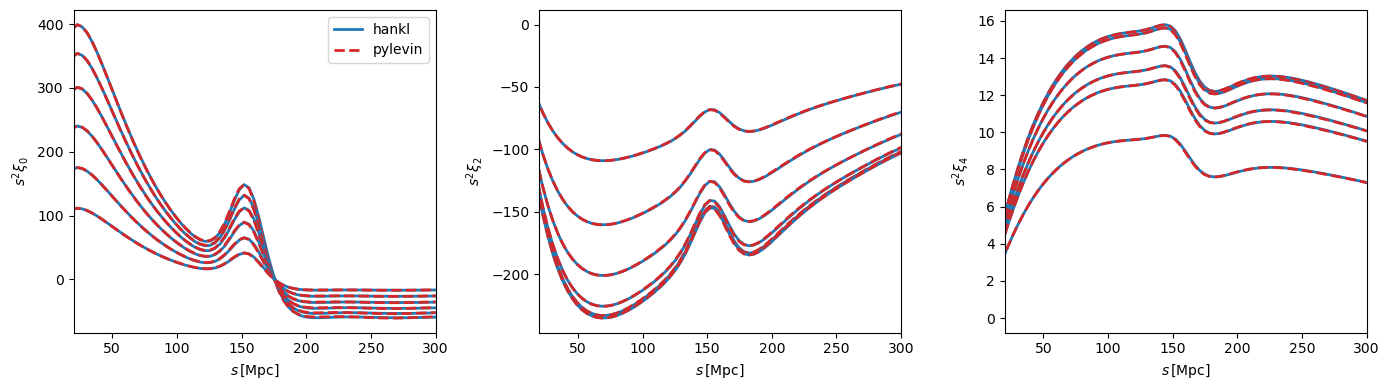

In [3]:
p_fiducial = kaiser_multipoles(cosmology(), k)
lp, result = new_instance(p_fiducial)
lp.levin_integrate_bessel_single(k_min, k_max, s_all, ell_all, result, integrand = integrand_all) # stores the rules
xi_fiducial = to_xi(result)

xi_direct = direct_integral(cosmology())
print("differences to the direct integral at z = 0 for ell = 0, 2, 4:")
print("  pylevin:", difference(xi_fiducial[:, :1], xi_direct))
print("  hankl:  ", difference(hankl_xi(p_fiducial)[:, :1], xi_direct))

fig, ax = plt.subplots(1, 3, figsize = (14, 4))
xi_hankl = hankl_xi(p_fiducial)
for l, ell in enumerate(multipoles):
    for z_i in range(len(a)):
        ax[l].plot(s, s**2*xi_hankl[l, z_i], color = "C0", lw = 2, label = "hankl" if z_i == 0 else None)
        ax[l].plot(s, s**2*xi_fiducial[l, z_i], color = "C3", ls = "--", lw = 2, label = "pylevin" if z_i == 0 else None)
    ax[l].set_xlim(20, s[-1]); ax[l].set_xlabel(r"$s\,[\mathrm{Mpc}]$"); ax[l].set_ylabel(rf"$s^2\xi_{ell}$")
ax[0].legend()
plt.tight_layout(); plt.show()

## Other cosmologies

We draw 20 cosmologies from a box around the fiducial one, which also moves the BAO peak by several Mpc. For the exported rules, the power spectrum is evaluated with CCL directly at the nodes, so no interpolation is needed.

With `logy = False`, the spline of the samples is linear in them, so the exported rules and the spline also combine into one matrix `W`: the integral for separation `s[i]` over integrand `j`, one of the 18 functions $k^2 P_\ell(k, z)$, is `W[j, i] @ f[:, j]`. This reproduces `update_integrand` exactly, and many cosmologies are integrated at once by one batched matrix product. Building `W` takes a moment, but only once.

All results are compared with a new instance at all redshifts, and with the direct integral at $z = 0$ (which takes most of the time of this cell).

In [ ]:
x_nodes, weights, offsets = lp.get_quadrature()
integral = np.repeat(np.arange(len(offsets) - 1), np.diff(offsets)) # integral of each node
node_integrand = integrand_all[integral] # (ell, z) of each node
node_ell, node_z = np.divmod(node_integrand, len(a))
print(len(x_nodes), "nodes for", len(offsets) - 1, "integrals")

def rule(p_nodes):
    # the exported rules for P_ell evaluated at the nodes, shape (3, len(a), len(x_nodes))
    f_nodes = x_nodes**2*p_nodes[node_ell, node_z, np.arange(len(x_nodes))]
    return np.bincount(integral, weights*f_nodes, minlength = len(offsets) - 1)

def rule_matrix(lp, x, chunk = 4000):
    # W with W[p] @ f = integral p for samples f on x: the stored rules times the spline of
    # pylevin (not-a-knot in log x, zero outside x)
    x_nodes, weights, offsets = lp.get_quadrature()
    integral = np.repeat(np.arange(len(offsets) - 1), np.diff(offsets))
    spline = CubicSpline(np.log(x), np.eye(len(x)))
    W = np.zeros((len(offsets) - 1, len(x)))
    for start in range(0, len(x_nodes), chunk):
        part = slice(start, start + chunk)
        nodes = x_nodes[part]
        values = spline(np.log(nodes))*((nodes >= x[0]) & (nodes <= x[-1]))[:, None]
        rule = sparse.csr_matrix((weights[part], (integral[part], np.arange(len(nodes)))), shape = (len(offsets) - 1, len(nodes)))
        W += rule @ values
    return W

W = rule_matrix(lp, k).reshape(n_integrands, len(s), len(k)) # (integrand, s, k)

def matrix_xi(f):
    # xi_ell for samples f of shape (integrand, k, cosmology), shape (3, len(a), len(s), cosmology)
    return sign[..., None]*(W @ f).reshape(len(multipoles), len(a), len(s), f.shape[-1])/(2*np.pi**2)

rng = np.random.default_rng(1)

cosmologies = [dict(Omega_c = rng.uniform(0.15, 0.5), h = rng.uniform(0.5, 1), n_s = rng.uniform(0.8, 1.2), sigma8 = rng.uniform(0.6, 1))
               for _ in range(20)]


comparison = {"update_integrand vs new instance": [], "exported rules vs new instance": [], "matrix product vs new instance": [], "hankl vs new instance": []}
accuracy = {"update_integrand": [], "exported rules": [], "matrix product": [], "new instance": [], "hankl": []} # vs the direct integral at z = 0
timing = {"new instance": [], "update_integrand + repeated call": [], "exported rules (numpy)": [], "matrix product, one cosmology": [], "hankl": []}
xi_examples, f_all = [], []
for parameters in cosmologies:
    cosmo = cosmology(**parameters)
    p_ell = kaiser_multipoles(cosmo, k)

    t0 = time.perf_counter()
    lp.update_integrand(k, integrands(p_ell), True, False)
    lp.levin_integrate_bessel_single(k_min, k_max, s_all, ell_all, result, integrand = integrand_all)
    timing["update_integrand + repeated call"].append(time.perf_counter() - t0)
    xi_updated = to_xi(result)

    t0 = time.perf_counter()
    _, result_new = new_instance(p_ell)
    timing["new instance"].append(time.perf_counter() - t0)
    xi_new = to_xi(result_new)

    p_nodes = kaiser_multipoles(cosmo, x_nodes)
    t0 = time.perf_counter()
    xi_rule = to_xi(rule(p_nodes))
    timing["exported rules (numpy)"].append(time.perf_counter() - t0)

    f = integrands(p_ell).T[:, :, None] # (integrand, k, 1)
    f_all.append(f)
    t0 = time.perf_counter()
    xi_matrix = matrix_xi(f)[..., 0]
    timing["matrix product, one cosmology"].append(time.perf_counter() - t0)

    t0 = time.perf_counter()
    xi_h = hankl_xi(p_ell)
    timing["hankl"].append(time.perf_counter() - t0)

    comparison["update_integrand vs new instance"].append(difference(xi_updated, xi_new))
    comparison["exported rules vs new instance"].append(difference(xi_rule, xi_new))
    comparison["matrix product vs new instance"].append(difference(xi_matrix, xi_new))
    comparison["hankl vs new instance"].append(difference(xi_h, xi_new))
    xi_direct = direct_integral(cosmo)
    xi_examples.append((parameters, xi_updated, xi_new))

f_all = np.concatenate(f_all, -1) 
timing["matrix product, all 20 at once"] = [min(timeit.repeat(lambda: matrix_xi(f_all), number = 1, repeat = 5))/len(cosmologies)]

print("\ntime per cosmology:")
for name, values in timing.items():
    print(f"  {name:34s} {np.mean(values)*1e3:8.2f} ms")

264240 nodes for 1440 integrals

time per cosmology:
  new instance                         166.88 ms
  update_integrand + repeated call       2.40 ms
  exported rules (numpy)                 4.00 ms
  matrix product, one cosmology          1.22 ms
  hankl                                  4.44 ms
  matrix product, all 20 at once         0.02 ms


For all cosmologies, the updated instance and the exported rules agree with the direct integral to about the requested accuracy (`relative_accuracy = 1e-4` per integral) and the interpolation of the power spectrum on 1024 wavenumbers, and the updated instance is about a hundred times faster than a new one. The matrix product gives the same results as `update_integrand`, about equally fast for one cosmology and much faster for all of them at once. The exported rules work node by node and are therefore not faster on a CPU; they are for evaluating the integrand exactly at the nodes, or elsewhere, such as in `jax`. So the subintervals of the fiducial cosmology serve the whole prior range.

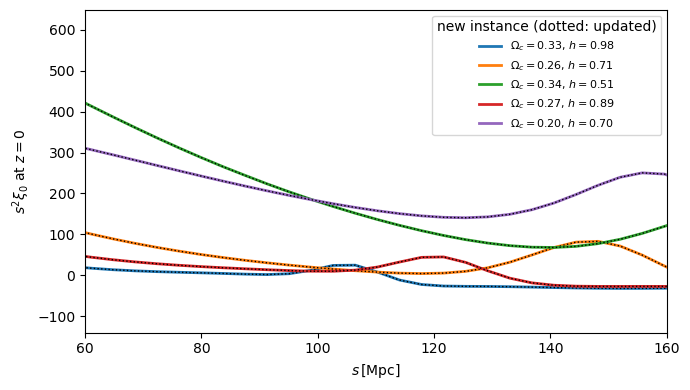

In [8]:
fig, ax = plt.subplots(figsize = (7, 4))
for i, (parameters, xi_updated, xi_new) in enumerate(xi_examples[:5]):
    label = rf"$\Omega_c = {parameters['Omega_c']:.2f}$, $h = {parameters['h']:.2f}$"
    ax.plot(s, s**2*xi_new[0, 0], color = f"C{i}", lw = 2, label = label)
    ax.plot(s, s**2*xi_updated[0, 0], color = "k", ls = ":", lw = 1)
ax.set_xlim(60, 160); ax.set_xlabel(r"$s\,[\mathrm{Mpc}]$"); ax.set_ylabel(r"$s^2\xi_0$ at $z = 0$")
ax.legend(fontsize = 8, title = "new instance (dotted: updated)")
plt.tight_layout(); plt.show()

## Many cosmologies at once

The matrix product pays off the more cosmologies are integrated at once, as in a sampler that evaluates many points together or for numerical derivatives. For a batch of 100:

In [9]:
n_batch = 100
batch = [dict(Omega_c = rng.uniform(0.22, 0.32), h = rng.uniform(0.62, 0.72), n_s = rng.uniform(0.92, 1.0), sigma8 = rng.uniform(0.72, 0.9))
         for _ in range(n_batch)]
p_batch = [kaiser_multipoles(cosmology(**parameters), k) for parameters in batch]
f_batch = np.stack([integrands(p_ell).T for p_ell in p_batch], -1) # (integrand, k, cosmology)

t_batch = min(timeit.repeat(lambda: matrix_xi(f_batch), number = 1, repeat = 5))/n_batch
xi_batch = matrix_xi(f_batch)

xi_levin = []
t0 = time.perf_counter()
for p_ell in p_batch:
    lp.update_integrand(k, integrands(p_ell), True, False)
    lp.levin_integrate_bessel_single(k_min, k_max, s_all, ell_all, result, integrand = integrand_all)
    xi_levin.append(to_xi(result))
t_levin = (time.perf_counter() - t0)/n_batch

print("batched matrix product vs update_integrand:",
      max(np.max(np.abs(xi_batch[..., b] - xi_levin[b]))/np.max(np.abs(xi_levin[b])) for b in range(n_batch)))
print(f"per cosmology: update_integrand + repeated call {t_levin*1e3:.3f} ms, batched matrix product {t_batch*1e3:.3f} ms ({t_levin/t_batch:.0f}x faster)")

batched matrix product vs update_integrand: 1.3643853636376012e-15
per cosmology: update_integrand + repeated call 0.371 ms, batched matrix product 0.018 ms (20x faster)
